# Preparación de datos demográficos, 2000-2022

**Estudiante:** Jorge Adalberto Zuñiga Oliva  
**Matrícula:** 82005 · **Grupo:** 512  
**Materia:** Tópicos de Big Data

In [1]:
from pathlib import Path
import sys
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/curso.py").exists())
sys.path.insert(0, str(RAIZ / "scripts"))
from curso import (leer_owid, metadatos, indicador, solo_paises, guardar_figura,
                   guardar_tabla, U1, U3, SALIDA, FUENTES)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_rows", 12)
pd.set_option("display.max_columns", 12)

## 1. Seleccionar históricos y revisar esquemas
Las fuentes contienen históricos y proyecciones en columnas separadas. Se seleccionan
**solo estimaciones históricas**, se conservan los años 2000-2022 y se unen por entidad y año.
Las entidades incluyen países y agregados; el modelado posterior filtrará códigos de tres letras.
Fuentes: [población](https://ourworldindata.org/grapher/population-with-un-projections),
[nacimientos](https://ourworldindata.org/grapher/number-of-births-per-year),
[defunciones](https://ourworldindata.org/grapher/number-of-deaths-per-year) y
[muertes de menores de 5](https://ourworldindata.org/grapher/number-of-child-deaths-unwpp).

In [2]:
especificaciones = {
    "population": ("population-with-un-projections", "population__sex_all__age_all__variant_estimates"),
    "births": ("number-of-births-per-year", "births__sex_all__age_all__variant_estimates"),
    "deaths": ("number-of-deaths-per-year", "deaths__sex_all__age_all__variant_estimates"),
    "child_deaths_under_5": ("number-of-child-deaths-unwpp", "deaths__sex_all__age_0_4__variant_estimates"),
}
tablas = {}
for variable, (slug, columna) in especificaciones.items():
    datos = indicador(slug, columna, variable)
    tablas[variable] = datos.loc[datos.year.between(2000, 2022)].copy()
    print(variable, tablas[variable].shape, "duplicadas:", tablas[variable].duplicated(["entity", "year"]).sum())
    display(tablas[variable].head(2))

population (6026, 4) duplicadas: 0


,entity,code,year,population
50,Afghanistan,AFG,2000,20130334.0
51,Afghanistan,AFG,2001,20284303.0


births (5957, 4) duplicadas: 0


,entity,code,year,births
50,Afghanistan,AFG,2000,1036525.0
51,Afghanistan,AFG,2001,1006562.0


deaths (5888, 4) duplicadas: 0


,entity,code,year,deaths
50,Afghanistan,AFG,2000,253804.0
51,Afghanistan,AFG,2001,242473.0


child_deaths_under_5 (5887, 4) duplicadas: 0


,entity,code,year,child_deaths_under_5
50,Afghanistan,AFG,2000,133112
51,Afghanistan,AFG,2001,125627


## 2. Unir y auditar cobertura
Una unión `inner` conserva las llaves compartidas. El informe muestra cuántas se pierden
en cada paso; no se rellenan datos inexistentes. El código de población se conserva como identificador.

In [3]:
base = tablas["population"].copy()
auditoria = [{"paso": "population", "filas": len(base)}]
for variable in ["births", "deaths", "child_deaths_under_5"]:
    base = base.merge(tablas[variable].drop(columns="code"), on=["entity", "year"], how="inner", validate="one_to_one")
    auditoria.append({"paso": f"+ {variable}", "filas": len(base)})
display(pd.DataFrame(auditoria))
display(base.isna().sum().to_frame("faltantes"))
antes = len(base)
variables = list(especificaciones)
base = base.dropna(subset=variables)
base = base.loc[base.population.gt(0) & base.births.gt(0)].sort_values(["entity", "year"]).reset_index(drop=True)
assert not base.empty and not base.duplicated(["entity", "year"]).any()
print("Filas completas:", len(base), "Descartadas tras unir:", antes-len(base))

,paso,filas
0,population,6026
1,+ births,5957
2,+ deaths,5819
3,+ child_deaths_under_5,5818


,faltantes
entity,0
code,115
year,0
population,0
births,0
deaths,0
child_deaths_under_5,0


Filas completas: 5818 Descartadas tras unir: 0


## 3. Conteos y tasas
Los nacimientos y defunciones son conteos anuales; la población corresponde al 1 de julio.
Las primeras dos tasas son por mil habitantes. La razón de muertes de menores de cinco
entre nacimientos del mismo año es **descriptiva**, no una probabilidad de morir antes de los cinco años.

,entity,code,year,population,births,deaths,child_deaths_under_5,birth_rate_per_1000,death_rate_per_1000,under5_deaths_per_1000_births_same_year
0,Afghanistan,AFG,2000,20130334.0,1036525.0,253804.0,133112,51.490701,12.608037,128.421408
1,Afghanistan,AFG,2001,20284303.0,1006562.0,242473.0,125627,49.622706,11.953726,124.808010
2,Afghanistan,AFG,2002,21378123.0,1015202.0,239161.0,123215,47.487892,11.187184,121.369934
3,Afghanistan,AFG,2003,22733053.0,1069727.0,243573.0,123894,47.056020,10.714487,115.818335
4,Afghanistan,AFG,2004,23560656.0,1095372.0,244435.0,122315,46.491575,10.374711,111.665261


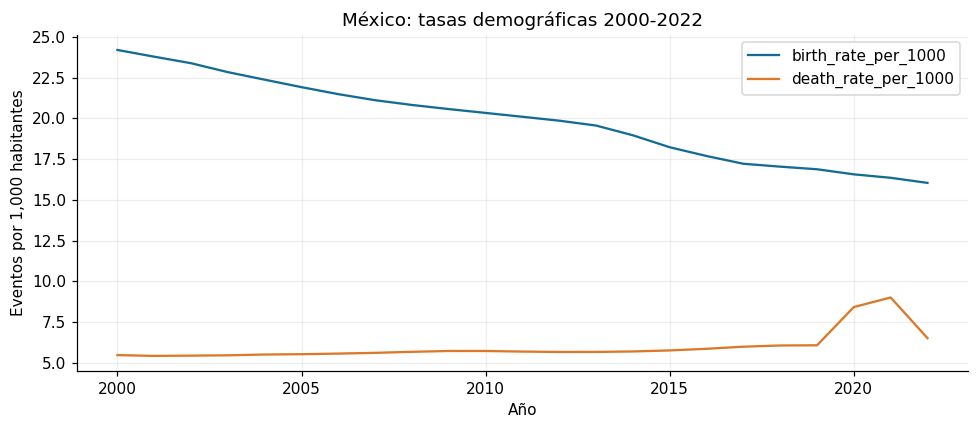

CSV guardado: U3_1_modelos_ml/data/processed/demografia_owid_2000_2022.csv (5,818 filas)
CSV guardado: U3_1_modelos_ml/data/processed/auditoria_union_demografia.csv (4 filas)


Se obtuvo un panel de **5,818 filas**, **253 entidades** y años **2000-2022**. Las cuatro variables están completas.

In [4]:
base["birth_rate_per_1000"] = 1000 * base.births / base.population
base["death_rate_per_1000"] = 1000 * base.deaths / base.population
base["under5_deaths_per_1000_births_same_year"] = 1000 * base.child_deaths_under_5 / base.births
display(base.head())
mexico = base.loc[base.entity.eq("Mexico")]
for variable in ["birth_rate_per_1000", "death_rate_per_1000"]:
    plt.plot(mexico.year, mexico[variable], label=variable)
plt.xlabel("Año"); plt.ylabel("Eventos por 1,000 habitantes")
plt.title("México: tasas demográficas 2000-2022"); plt.legend()
guardar_figura("U3_2_preparacion_tasas")
guardar_tabla(base, "demografia_owid_2000_2022.csv")
guardar_tabla(pd.DataFrame(auditoria), "auditoria_union_demografia.csv")
display(Markdown(f"Se obtuvo un panel de **{len(base):,} filas**, **{base.entity.nunique()} entidades** "
                 f"y años **{base.year.min()}-{base.year.max()}**. Las cuatro variables están completas."))

## 4. Conclusión
Unir por nombres de entidad y año hace explícita la unidad de observación. La validación
de llaves impide un producto cartesiano accidental. Para comparar tamaño relativo se usan
tasas; para estudiar volumen de eventos se conservan conteos. Se mantienen ambos para no confundirlos.